## Preparing data from TinyStories

**Project questions we explore**

1. Does a learned scalar gate on each attention head (G1) improve the next token prediction in held out settings,
      and how does it compare with a sink logit that make an attention head abstain.

2. Does the gated model benefit from choosing different gate values for different inputs?
3. Interesting setting to try would be Which predictions improve or get worse (1) repeated words within a story (2) name carry-over between unrelated stories?

In [ ]:
VOCAB_SIZE = 4096
BLOCK_SIZE = 256          # model context length
EVAL_STRIDE = 128         # sliding-window stride for held-out stories longer than BLOCK_SIZE (note: experiment more with other window sizes)
B_SCORED = 32             # boundary experiment (note: experiment more with other numbers)
MIN_A_TOKENS = 64         # A must be long enough to act as a distractor
DATA_SEED = 1234          # for consistency

In [ ]:
import os
import re
import json
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

#RUN_NAME = os.environ.get('GA_RUN', 'smoke')
#REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'experiments').is_dir())
#DATA_DIR = REPO_ROOT / 'processed_data' / 'gated_attention' / RUN_NAME
#DATA_DIR.mkdir(parents=True, exist_ok=True)
#print('run:', RUN_NAME, '| writing to', DATA_DIR.relative_to(REPO_ROOT))
#splits, tokenizer, packed training blocks, held-out windows, word table, story pairs, name-swap prompts

# - block_size: the model's context length (tokens). For training blocks and held-out windows.
# - All the Held-out splits are frpm the official TInystories validation split

# first Using 50,000 training stories to learn the vocabulary and how to splits text into tokens.
# then 1,500 set for calibration stories to measure each head’s average gate value. 
# Construct x pairs of stories, A and B. For each pair, we should measure how predictions in B change when the model can see A versus when access to A is blocked.


In [9]:
# for experimental run

BUDGETS = {
    'smoke': dict(n_train_stories=8_000, n_tokenizer_stories=8_000, n_val=150, n_calib=150, n_eval=300,
                  n_boundary_pairs=150, n_name_pairs=4, n_name_b_per_combo=1),
    'full':  dict(n_train_stories=125_000, n_tokenizer_stories=50_000, n_val=1_500, n_calib=1_500, n_eval=4_000,
                  n_boundary_pairs=2_000, n_name_pairs=None, n_name_b_per_combo=1),
}
budget = BUDGETS['full']
budget

{'n_train_stories': 125000,
 'n_tokenizer_stories': 50000,
 'n_val': 1500,
 'n_calib': 1500,
 'n_eval': 4000,
 'n_boundary_pairs': 2000,
 'n_name_pairs': None,
 'n_name_b_per_combo': 1}

## Load TinyStories

from HuggingFace

In [10]:
ds = load_dataset('roneneldan/TinyStories')
ds

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 2119719
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 21990
    })
})

In [16]:
def clean(text):
    return text.strip()

def text_hash(text):
    # exact-duplicate key: whitespace-normalized text
    return hashlib.md5(' '.join(text.split()).encode('utf-8')).hexdigest()

rng = np.random.default_rng(DATA_SEED)

# training stories and creating a dataframe out of it
train_rows = np.sort(rng.choice(len(ds['train']), size=budget['n_train_stories'], replace=False))
train_df = pd.DataFrame({'story_id': [f'train-{i:07d}' for i in train_rows],
                         'text': [clean(t) for t in ds['train'].select(train_rows)['text']]})

# to avoid duplicates when sampling
train_df['hash'] = train_df.text.map(text_hash)

# held-out pool
val_rows = rng.permutation(len(ds['validation']))
held_df = pd.DataFrame({'story_id': [f'validation-{i:07d}' for i in val_rows],
                        'text': [clean(t) for t in ds['validation'].select(val_rows)['text']]})
held_df['hash'] = held_df.text.map(text_hash)
len(train_df), len(held_df)

(125000, 21990)

In [17]:
train_df

,story_id,text,hash
0,train-0000030,"Once upon a time, there was a boy named Tom. H...",d8fa348b50fd60ef3bc0b0a93ae07d67
1,train-0000031,"Once upon a time, there was a little boy named...",86ee82075f62a59458056f14c184d89b
2,train-0000044,"Once upon a time, there was a little girl name...",a7bd1dfb2eaef9207f68cf91bb302ebb
3,train-0000078,"Once, there were two friends who were playing ...",35edbcd18163a0213dcbe22aacc6c178
4,train-0000097,Once upon a time a little girl named Jill had ...,033572a0f256205cb28673dd7ed3a4c1
...,...,...,...
124995,train-2119689,"Once upon a time, there was a girl named Lily....",86c56b88684d4238c4297d7ecfbc6aea
124996,train-2119693,"Once upon a time, there was a little chick nam...",cd9dac4a8d724f0cebfa78b0c7f45c76
124997,train-2119697,"One day, a boy named Tim went to the park with...",3e1e036755bdd85ea5c755c385843a41
124998,train-2119698,"Once upon a time, there was a little girl name...",be32c074d506f0eca3486c888678d71f


### Exact-duplicate check

TinyStories has couple of problems which are existing of repeated stories (can get rid of using whitespace normalized text) and empty stories (drop them) and do this across training and held out sets.
After this, no text is shared between any two splits we use.

In [20]:
all_train_hashes = set()
for batch in ds['train'].iter(batch_size=100_000):
    all_train_hashes.update(text_hash(clean(t)) for t in batch['text'])

dup_report = {}
dup_report['train_empty'] = int((train_df.text == '').sum())
dup_report['train_within_dup'] = int(train_df.hash.duplicated().sum())
train_df = train_df[(train_df.text != '') & ~train_df.hash.duplicated()].reset_index(drop=True)

dup_report['heldout_empty'] = int((held_df.text == '').sum())
dup_report['heldout_within_dup'] = int(held_df.hash.duplicated().sum())
dup_report['heldout_in_official_train'] = int(held_df.hash.isin(all_train_hashes).sum())
held_df = held_df[(held_df.text != '') & ~held_df.hash.duplicated() & ~held_df.hash.isin(all_train_hashes)].reset_index(drop=True)
dup_report

{'train_empty': 11,
 'train_within_dup': 1036,
 'heldout_empty': 0,
 'heldout_within_dup': 0,
 'heldout_in_official_train': 6601}

## Tokenizer

Fitting a small byte level BPE tokenizer (4,096 tokens) on training stories only. (Attaching the leaning space to the following word)

In [ ]:
# fix the error in below line: Exception: No such file or directory (os error 2)
# EOS: story A <|endoftext|> story B
# PAD tp when we have elss number of tokens for a story.

PAD means padding. <|pad|> fills empty positions when sequences of different lengths need to fit in the same batch. I

DATA_DIR = Path('processed_data/gated_attention')
DATA_DIR.mkdir(parents=True, exist_ok=True)

tok_texts = train_df.text.iloc[:budget['n_tokenizer_stories']].tolist()
tokenizer = Tokenizer(models.BPE())
tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tokenizer.decoder = decoders.ByteLevel()
trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, min_frequency=2,
                              special_tokens=['<|endoftext|>', '<|pad|>'],
                              initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=False)
tokenizer.train_from_iterator(tok_texts, trainer)
EOS_ID, PAD_ID = tokenizer.token_to_id('<|endoftext|>'), tokenizer.token_to_id('<|pad|>')
tokenizer.save(str(DATA_DIR / 'tokenizer.json'))
print('vocab size', tokenizer.get_vocab_size(), '| EOS', EOS_ID, '| PAD', PAD_ID)
enc = tokenizer.encode('Lily found a kite. Lily ran home.')
list(zip(enc.tokens, enc.offsets))

vocab size 4096 | EOS 0 | PAD 1


[('Lily', (0, 4)),
 ('Ġfound', (4, 10)),
 ('Ġa', (10, 12)),
 ('Ġkite', (12, 17)),
 ('.', (17, 18)),
 ('ĠLily', (18, 23)),
 ('Ġran', (23, 27)),
 ('Ġhome', (27, 32)),
 ('.', (32, 33))]

## Splits

In [ ]:
n_val, n_calib, n_eval = budget['n_val'], budget['n_calib'], budget['n_eval']
#assert n_val + n_calib + n_eval <= len(held_df), 'not enough held-out stories'

held_df['split'] = None
held_df.loc[:n_val - 1, 'split'] = 'val'
held_df.loc[n_val:n_val + n_calib - 1, 'split'] = 'calib'
held_df.loc[n_val + n_calib:n_val + n_calib + n_eval - 1, 'split'] = 'eval'
held_df = held_df[held_df.split.notna()].reset_index(drop=True)
#main dfs split
train_df['split'] = 'train'

stories = pd.concat([train_df, held_df], ignore_index=True)
encodings = tokenizer.encode_batch(stories.text.tolist())
stories['ids'] = [e.ids for e in encodings]
stories['n_tokens'] = stories.ids.map(len)
stories['n_words'] = stories.text.map(lambda t: len(t.split()))

# no exact text is shared between splits
#assert stories.groupby('hash').split.nunique().max() == 1
#assert stories.story_id.is_unique

manifest = stories[['story_id', 'split', 'n_tokens', 'n_words', 'hash']]
manifest.to_csv(DATA_DIR / 'split_manifest.csv', index=False)
split_counts = manifest.groupby('split').agg(stories=('story_id', 'size'), tokens=('n_tokens', 'sum'),
                                             median_tokens=('n_tokens', 'median'), max_tokens=('n_tokens', 'max'))
split_counts

,stories,tokens,median_tokens,max_tokens
split,,,,
calib,1500,321568,193.0,986
eval,4000,839199,189.0,1058
train,123963,28207071,196.0,1170
val,1500,322602,192.0,903


In [26]:
manifest

,story_id,split,n_tokens,n_words,hash
0,train-0000030,train,186,157,d8fa348b50fd60ef3bc0b0a93ae07d67
1,train-0000031,train,166,135,86ee82075f62a59458056f14c184d89b
2,train-0000044,train,208,167,a7bd1dfb2eaef9207f68cf91bb302ebb
3,train-0000078,train,227,143,35edbcd18163a0213dcbe22aacc6c178
4,train-0000097,train,229,192,033572a0f256205cb28673dd7ed3a4c1
...,...,...,...,...,...
130958,validation-0009382,eval,129,104,52d6df80caaa8b50e0411a49f32d4610
130959,validation-0018972,eval,131,99,75d1c59ba52f6f07ce0fc31bed6067fb
130960,validation-0004474,eval,150,123,a8c4f97d82a2444c7c5cde8fa98c5b0e
130961,validation-0000426,eval,159,131,796c06f3544e1e1e9cb9bd15f388fa8e


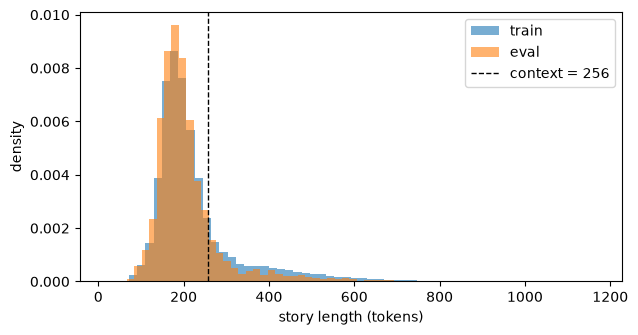

In [ ]:
plt.figure(figsize=(7, 3.5))
plt.hist(stories.n_tokens[stories.split == 'train'], bins=60, alpha=.6, density=True, label='train')
plt.hist(stories.n_tokens[stories.split == 'eval'], bins=60, alpha=.6, density=True, label='eval')
plt.axvline(BLOCK_SIZE, color='k', ls='--', lw=1, label=f'context = {BLOCK_SIZE}')
plt.xlabel('story length (tokens)')
plt.ylabel('density')
plt.legend()
plt.show()


# theres a considerate amount of stories that are longer than BLOCK_SIZE

In [29]:
# stories longer than BLOCK_SIZE
long_stories = stories[stories.n_tokens > BLOCK_SIZE]
print(len(long_stories))

27015


## Training blocks: several stories per sequence, separated by EOS

Like EOS s1 EOS s2 EOS s3 and the cut into blocks by 'BLOCK_SIZE + 1' tokens (+ 1 making consecutive blocks overlap by one token)

In [30]:
train_stories = stories[stories.split == 'train'].sample(frac=1, random_state=DATA_SEED).reset_index(drop=True)
pieces, seg_story, seg_first = [], [], []
pos = 0
for sid, ids in zip(train_stories.story_id, train_stories.ids):
    pieces.append(np.array([EOS_ID] + ids, dtype=np.uint16))
    seg_story.append(sid)
    seg_first.append(pos + 1)            # stream position of the story's first token
    pos += len(ids) + 1
stream = np.concatenate(pieces)
seg_first = np.array(seg_first)
seg_end = np.append(seg_first[1:] - 1, len(stream))   # exclusive; the next EOS is not part of the story

n_blocks = (len(stream) - 1) // BLOCK_SIZE
train_blocks = np.stack([stream[b * BLOCK_SIZE: b * BLOCK_SIZE + BLOCK_SIZE + 1] for b in range(n_blocks)])
np.save(DATA_DIR / 'train_blocks.npy', train_blocks)

rows = []
for b in range(n_blocks):
    lo, hi = b * BLOCK_SIZE, b * BLOCK_SIZE + BLOCK_SIZE + 1
    k0 = max(np.searchsorted(seg_first, lo, side='right') - 1, 0)
    k1 = np.searchsorted(seg_first, hi, side='left')
    for k in range(k0, k1):
        if seg_end[k] <= lo:
            continue
        rows.append((b, seg_story[k], max(seg_first[k] - lo, 0), min(seg_end[k], hi) - lo, seg_first[k] - 1 - lo))
train_boundaries = pd.DataFrame(rows, columns=['block', 'story_id', 'seg_start', 'seg_end', 'eos_pos'])
train_boundaries.to_parquet(DATA_DIR / 'train_boundaries.parquet', index=False)

print(f'{len(stream):,} training tokens -> {n_blocks:,} blocks of {BLOCK_SIZE + 1}')
print('stories per block (mean):', round(train_boundaries.groupby('block').size().mean(), 2))
train_boundaries.head(6)

28,331,034 training tokens -> 110,668 blocks of 257
stories per block (mean): 2.12


,block,story_id,seg_start,seg_end,eos_pos
0,0,train-1379249,1,257,0
1,1,train-1379249,0,257,-256
2,2,train-1379249,0,131,-512
3,2,train-0487990,132,257,131
4,3,train-0487990,0,47,-125
5,3,train-0506303,48,227,47


In [ ]:
# checking the token right before every story segment that starts inside a block is EOS
inside = train_boundaries[train_boundaries.eos_pos >= 0]
assert (train_blocks[inside.block.values, inside.eos_pos.values] == EOS_ID).all()
print(repr(tokenizer.decode(train_blocks[0][:80].tolist(), skip_special_tokens=False)))

'<|endoftext|>Ben and Lily were twins who liked to play with their toy train. They had a big track that went around their room and a shiny red engine that made noise and smoke. They also had a small wagon that carried coal, the black rocks that made the engine go.\n\nOne day, they decided to play a trick on their dad, who was working in his office. They took'


## Held-out windows

so the first story token is predicted from EOS, just as after a boundary in training. 
The target index target_pos is the position of the token in the story (0 = first token).

In order to deal with stories that are longer than the size i set, we have to use a sliding window because when it comes ot a target in a longer story, it dont have access to the begining context.

In [31]:
def story_windows(story_id, ids, block_size=BLOCK_SIZE, stride=EVAL_STRIDE):
    seq = [EOS_ID] + list(ids)
    n = len(ids)                       # number of targets
    offsets = [0]
    while offsets[-1] + block_size < n:
        offsets.append(min(offsets[-1] + stride, n - block_size))
    windows, scored_upto = [], 0
    for o in offsets:
        n_in = min(block_size, n - o)
        windows.append(dict(story_id=story_id, offset=o, score_from=scored_upto - o,
                            tokens=seq[o:o + n_in + 1]))
        scored_upto = o + n_in
    return windows

for split in ['val', 'calib', 'eval']:
    part = stories[stories.split == split]
    windows = [w for sid, ids in zip(part.story_id, part.ids) for w in story_windows(sid, ids)]
    wdf = pd.DataFrame(windows)
    wdf.insert(0, 'window_id', [f'{split}-w{i:06d}' for i in range(len(wdf))])
    wdf.to_parquet(DATA_DIR / f'{split}_windows.parquet', index=False)
    n_targets = sum(len(w['tokens']) - 1 - w['score_from'] for w in windows)
    assert n_targets == part.n_tokens.sum()          # every story token scored exactly once
    print(f'{split:5s}: {len(part):5d} stories -> {len(wdf):5d} windows, {n_targets:,} scored targets')

eval_windows = pd.read_parquet(DATA_DIR / 'eval_windows.parquet')

val  :  1500 stories ->  1883 windows, 322,602 scored targets
calib:  1500 stories ->  1873 windows, 321,568 scored targets
eval :  4000 stories ->  4898 windows, 839,199 scored targets


## Held-out word-occurrence table

For every eval story we list each word and whether it is the first mention of that word in the story or a repeat.


### this is the definition from the Qiu Zihan's paper and for below codes AI assisted in building up logic

**Word and normalization rule.** A word is a run of letters, optionally with apostrophe parts: regex `[A-Za-z]+(?:['’][A-Za-z]+)*` (so `don't` and `Lily's` are one word each). The **normalized form** is the lowercased word with `’` mapped to `'` and a final possessive `'s` removed: `Lily`, `lily` and `Lily's` all normalize to `lily`; `dog` and `dogs` stay different (no stemming).

**Token span.** With byte-level BPE the space before a word belongs to the word's first token. A word is *eligible* as a target when its tokens line up exactly with the word: the first token starts at the preceding space (or at the word itself if there is no space before it) and the last token ends at the word's end. Its loss is the sum over these subtokens.

**Repeat distance.** For a repeat, `distance_words` is the number of words between this occurrence and the most recent earlier occurrence of the same normalized form in the same story (1 = the previous word). `prev_visible` says whether that earlier occurrence lies inside the context window used to score the word's first subtoken.

In [37]:
WORD_RE = re.compile(r"[A-Za-z]+(?:['’][A-Za-z]+)*")
FUNCTION_WORDS = set('''a an the and or but if so then than to of in on at by for with from up down out over under
into onto about as is was were be been am are it its it's he she they we you i me him her them us my your his their our
this that these those there here not no yes do did does don't didn't can could will would should what who when where why how
one all some very too also just said says'''.split())

def normalize(word):
    w = word.lower().replace('’', "'")
    return w[:-2] if w.endswith("'s") else w

# window that scores each story target -> its offset (to decide what is visible)
scoring_offset = {}
for r in eval_windows.itertuples():
    n_in = len(r.tokens) - 1
    for t in range(r.offset + r.score_from, r.offset + n_in):
        scoring_offset[(r.story_id, t)] = r.offset

word_rows = []
eval_stories = stories[stories.split == 'eval']
for sid, text, enc in tqdm(zip(eval_stories.story_id, eval_stories.text, tokenizer.encode_batch(eval_stories.text.tolist())),
                           total=len(eval_stories), desc='word table'):
    ids, offs = enc.ids, enc.offsets
    starts = {s: i for i, (s, e) in enumerate(offs)}
    ends = {e: i for i, (s, e) in enumerate(offs)}
    tok_starts = np.array([s for s, e in offs])
    last_seen = {}                        # norm -> (word_idx, first token index)
    for word_idx, m in enumerate(WORD_RE.finditer(text)):
        a, b = m.span()
        surface, norm = m.group(), normalize(m.group())
        first_tok = int(np.searchsorted(tok_starts, a, side='right') - 1)   # token containing the word start
        lead = a - 1 if a > 0 and text[a - 1] == ' ' else a
        t0, t1 = starts.get(lead), ends.get(b)
        prev = last_seen.get(norm)
        if t0 is not None and t1 is not None and t0 <= t1:
            o = scoring_offset[(sid, t0)]
            word_rows.append(dict(
                story_id=sid, word_idx=word_idx, surface=surface, norm=norm,
                char_start=lead, char_end=b, tok_start=t0, tok_end=t1 + 1, n_subtokens=t1 + 1 - t0,
                occurrence='first' if prev is None else 'repeat',
                distance_words=np.nan if prev is None else word_idx - prev[0],
                prev_tok_start=-1 if prev is None else prev[1],
                window_offset=o,
                prev_visible=None if prev is None else bool(prev[1] >= max(o - 1, 0)),
                is_function_word=norm in FUNCTION_WORDS,
                is_capitalized=surface[0].isupper() and lead > 0 and text[lead - 1] not in '.!?"\n',
            ))
        last_seen[norm] = (word_idx, first_tok)

words = pd.DataFrame(word_rows)
words.insert(0, 'word_id', np.arange(len(words)))
words.to_parquet(DATA_DIR / 'eval_words.parquet', index=False)
print(f'{len(words):,} eligible target words in {words.story_id.nunique()} eval stories')
words.head(8)

word table: 100%|██████████| 4000/4000 [00:03<00:00, 1235.34it/s]


650,682 eligible target words in 4000 eval stories


,word_id,story_id,word_idx,surface,norm,char_start,char_end,tok_start,tok_end,n_subtokens,occurrence,distance_words,prev_tok_start,window_offset,prev_visible,is_function_word,is_capitalized
0,0,validation-0015907,0,Once,once,0,4,0,1,1,first,NaN,-1,0,None,False,False
1,1,validation-0015907,1,upon,upon,4,9,1,2,1,first,NaN,-1,0,None,False,False
2,2,validation-0015907,2,a,a,9,11,2,3,1,first,NaN,-1,0,None,True,False
3,3,validation-0015907,3,time,time,11,16,3,4,1,first,NaN,-1,0,None,False,False
4,4,validation-0015907,4,there,there,16,22,4,5,1,first,NaN,-1,0,None,True,False
5,5,validation-0015907,5,was,was,22,26,5,6,1,first,NaN,-1,0,None,True,False
6,6,validation-0015907,6,a,a,26,28,6,7,1,repeat,4.0,2,0,True,True,False
7,7,validation-0015907,7,small,small,28,34,7,8,1,first,NaN,-1,0,None,False,False


**Verification:** decode every saved token span and compare it with the original text (including the leading space). Every row must match exactly.

In [38]:
story_ids = dict(zip(eval_stories.story_id, eval_stories.ids))
story_text = dict(zip(eval_stories.story_id, eval_stories.text))
bad = 0
for r in words.itertuples():
    decoded = tokenizer.decode(story_ids[r.story_id][r.tok_start:r.tok_end])
    if decoded != story_text[r.story_id][r.char_start:r.char_end] or decoded.strip() != r.surface:
        bad += 1
print('span mismatches:', bad, 'of', len(words))
assert bad == 0
ex = words[words.n_subtokens > 1].head(5)
[(r.surface, [tokenizer.id_to_token(i) for i in story_ids[r.story_id][r.tok_start:r.tok_end]]) for r in ex.itertuples()]

span mismatches: 0 of 650682


[('swooped', ['Ġsw', 'oo', 'ped']),
 ('rescued', ['Ġresc', 'ued']),
 ('Being', ['ĠBe', 'ing']),
 ('rescue', ['Ġresc', 'ue']),
 ('frame', ['Ġfr', 'ame'])]

### Counts by diagnostic category

Distance bins (in words to the previous occurrence) used in notebook 04: **1–10**, **11–50**, **51+**.

In [39]:
DIST_BINS = [0, 10, 50, np.inf]
DIST_LABELS = ['repeat 1-10', 'repeat 11-50', 'repeat 51+']
words['category'] = np.where(words.occurrence == 'first', 'first',
                             pd.cut(words.distance_words, DIST_BINS, labels=DIST_LABELS).astype(str))
cat_counts = (words.groupby(['category'])
              .agg(n=('word_id', 'size'), stories=('story_id', 'nunique'),
                   multi_token=('n_subtokens', lambda s: int((s > 1).sum())),
                   prev_not_visible=('prev_visible', lambda s: int((s == False).sum())))
              .reindex(['first'] + DIST_LABELS))
cat_counts

,n,stories,multi_token,prev_not_visible
category,,,,
first,331458,4000,21887,0
repeat 1-10,90697,4000,2612,0
repeat 11-50,172677,3999,8790,0
repeat 51+,55850,3966,2264,4253


In [40]:
pd.crosstab(words.category, words.n_subtokens).reindex(['first'] + DIST_LABELS)

n_subtokens,1,2,3,4,5,6,8
category,,,,,,,
first,309571,15846,4545,1217,244,34,1
repeat 1-10,88085,1887,566,121,38,0,0
repeat 11-50,163887,6276,1857,498,156,3,0
repeat 51+,53586,1628,484,109,41,2,0


## Natural story pairs for the boundary experiment (A + EOS + B)

Two different eval stories, A and B, are joined as `EOS A EOS B[:32]`.
- A is used whole and must have 64–222 tokens, so it supplies a real distractor and leaves room for B in the 256-token context.
- Exactly the first 32 tokens of B are kept and scored (B must have at least 32 tokens). The same token sequence is used in every condition, so the B opening is never truncated differently.
- `eos_idx` is the index of the EOS between A and B; B targets are at sequence positions `eos_idx+1 ... eos_idx+32`.
- `tokens_alt` replaces A by the first `n_A` tokens of a third story (same length) — notebook 05 uses it to verify the mask.

In [41]:
prng = np.random.default_rng(DATA_SEED + 1)
ev = eval_stories.reset_index(drop=True)
max_a = BLOCK_SIZE - 2 - B_SCORED
a_pool = ev.index[(ev.n_tokens >= MIN_A_TOKENS) & (ev.n_tokens <= max_a)].to_numpy()
b_pool = ev.index[ev.n_tokens >= B_SCORED].to_numpy()
cap_names = lambda t: set(re.findall(r'(?<=[a-z,] )[A-Z][a-z]+', t))

pairs = []
for i, a in enumerate(prng.choice(a_pool, size=min(budget['n_boundary_pairs'], len(a_pool)), replace=False)):
    b = prng.choice(b_pool)
    while b == a:
        b = prng.choice(b_pool)
    A, B = ev.ids[a], ev.ids[b][:B_SCORED]
    alt_pool = ev.index[(ev.n_tokens >= len(A)) & (ev.index != a) & (ev.index != b)]
    c = prng.choice(alt_pool)
    tokens = [EOS_ID] + A + [EOS_ID] + B
    tokens_alt = [EOS_ID] + ev.ids[c][:len(A)] + [EOS_ID] + B
    eos_idx = 1 + len(A)
    pairs.append(dict(pair_id=i, story_id_a=ev.story_id[a], story_id_b=ev.story_id[b], story_id_alt=ev.story_id[c],
                      n_a=len(A), eos_idx=eos_idx, tokens=tokens, tokens_alt=tokens_alt,
                      b_target_positions=list(range(eos_idx + 1, eos_idx + 1 + B_SCORED)),
                      shared_capitalized=len(cap_names(ev.text[a]) & cap_names(ev.text[b])) > 0))
boundary_pairs = pd.DataFrame(pairs)
assert (boundary_pairs.tokens.map(len) <= BLOCK_SIZE + 1).all()
assert (boundary_pairs.apply(lambda r: r.tokens[r.eos_idx] == EOS_ID and len(r.tokens) - 1 - r.eos_idx == B_SCORED, axis=1)).all()
boundary_pairs.to_parquet(DATA_DIR / 'boundary_pairs.parquet', index=False)
print(len(boundary_pairs), 'pairs; A length', boundary_pairs.n_a.describe()[['min', '50%', 'max']].to_dict())
r = boundary_pairs.iloc[0]
print(repr(tokenizer.decode(r.tokens[r.eos_idx - 30:], skip_special_tokens=False)))

2000 pairs; A length {'min': 68.0, '50%': 175.0, 'max': 222.0}
' loaded the fuel onto its boat and sailed away. It had an amazing adventure and was glad that it found the fuel. The end.<|endoftext|>Once upon a time, there were two friends who liked to work together. One day, they decided to go to the post office to buy stamps. When'


## Controlled name-swap pairs

Two versions of a short story A differ **only** in the protagonist's name (e.g. Lily vs Emma). Both are followed by the same story B about a third person, which stops where a name is a natural next word (`"... One day,"`). Notebook 05 compares log P(Lily) − log P(Emma) at that point after each version of A.

Checks done here:
- every name is a **single token** with its leading space (` Lily`), which is the form scored at the continuation;
- the two versions of A have the **same number of tokens** and differ only at the name positions, so B starts at the same position in both;
- names and templates are rotated: every unordered name pair × every A template × every B template, with the B protagonist rotated over the remaining names.

In [42]:
NAME_POOL = ['Lily', 'Emma', 'Mia', 'Anna', 'Lucy', 'Sue', 'Amy', 'Sara', 'Kate',
             'Tom', 'Ben', 'Tim', 'Sam', 'Max', 'Jack', 'Bob', 'Joe', 'Mark']
A_TEMPLATES = [
    '{N} found a red kite in the park. {N} ran home to show Mom. Mom smiled at {N}.',
    'Once upon a time, {N} had a big blue ball. {N} played with the ball all day. At night, {N} was very tired.',
    '{N} wanted to bake a cake. {N} got eggs and milk. The cake was yummy, and {N} was happy.',
    'One sunny day, {N} went to the beach. {N} built a big sand castle. A wave came, but {N} just laughed.',
    '{N} saw a little bird in the tree. The bird was sad. {N} gave the bird some food, and the bird sang for {N}.',
]
B_TEMPLATES = [
    '{M} had a little boat. One day,',
    'There was a kid named {M}. {M} liked to play in the garden. Every morning,',
    '{M} had a toy car. The car was fast and shiny. Then',
    '{M} lived in a small house near the woods. One night,',
]

def single_token(name):
    return len(tokenizer.encode(' ' + name).ids) == 1

names = [n for n in NAME_POOL if single_token(n)]
print('names that are one token with a leading space:', names)
print('rejected:', [n for n in NAME_POOL if n not in names])

names that are one token with a leading space: ['Lily', 'Emma', 'Mia', 'Anna', 'Lucy', 'Sue', 'Amy', 'Sara', 'Tom', 'Ben', 'Tim', 'Sam', 'Max', 'Jack', 'Bob', 'Joe', 'Mark']
rejected: ['Kate']


In [43]:
nrng = np.random.default_rng(DATA_SEED + 2)
name_pairs = [(n1, n2) for i, n1 in enumerate(names) for n2 in names[i + 1:]]
if budget['n_name_pairs'] is not None:
    name_pairs = [name_pairs[i] for i in nrng.choice(len(name_pairs), budget['n_name_pairs'], replace=False)]

prompts, rejected = [], 0
for n1, n2 in name_pairs:
    others = [n for n in names if n not in (n1, n2)]
    for ta, a_tmpl in enumerate(A_TEMPLATES):
        for tb, b_tmpl in enumerate(B_TEMPLATES):
            for nb in nrng.choice(others, budget['n_name_b_per_combo'], replace=False):
                a1 = tokenizer.encode(a_tmpl.format(N=n1)).ids
                a2 = tokenizer.encode(a_tmpl.format(N=n2)).ids
                b = tokenizer.encode(b_tmpl.format(M=nb)).ids
                diff = [i for i in range(min(len(a1), len(a2))) if a1[i] != a2[i]]
                if len(a1) != len(a2) or len(diff) != a_tmpl.count('{N}'):
                    rejected += 1
                    continue
                t1, t2 = [EOS_ID] + a1 + [EOS_ID] + b, [EOS_ID] + a2 + [EOS_ID] + b
                prompts.append(dict(prompt_id=len(prompts), template_a=ta, template_b=tb,
                                    name_1=n1, name_2=n2, name_b=str(nb),
                                    id_1=tokenizer.token_to_id('Ġ' + n1), id_2=tokenizer.token_to_id('Ġ' + n2),
                                    id_b=tokenizer.token_to_id('Ġ' + nb),
                                    tokens_1=t1, tokens_2=t2, eos_idx=1 + len(a1), score_pos=len(t1) - 1,
                                    text_1=a_tmpl.format(N=n1) + ' <EOS> ' + b_tmpl.format(M=nb),
                                    text_2=a_tmpl.format(N=n2) + ' <EOS> ' + b_tmpl.format(M=nb)))
name_prompts = pd.DataFrame(prompts)
assert (name_prompts.tokens_1.map(len) == name_prompts.tokens_2.map(len)).all()
assert (name_prompts[['id_1', 'id_2', 'id_b']] != None).all().all()
# the scored candidates decode back to ' Name'
assert all(tokenizer.decode([r.id_1]) == ' ' + r.name_1 for r in name_prompts.itertuples())
name_prompts.to_parquet(DATA_DIR / 'name_swap_prompts.parquet', index=False)
print(len(name_prompts), 'matched prompt pairs;', rejected, 'rejected for unequal tokenization')
print(name_prompts.text_1.iloc[0])
print(name_prompts.text_2.iloc[0])

2348 matched prompt pairs; 372 rejected for unequal tokenization
Once upon a time, Lily had a big blue ball. Lily played with the ball all day. At night, Lily was very tired. <EOS> Max had a little boat. One day,
Once upon a time, Emma had a big blue ball. Emma played with the ball all day. At night, Emma was very tired. <EOS> Max had a little boat. One day,


In [44]:
pd.crosstab(name_prompts.template_a, name_prompts.template_b, margins=True)

template_b,0,1,2,3,All
template_a,,,,,
0,105,105,105,105,420
1,136,136,136,136,544
2,105,105,105,105,420
3,136,136,136,136,544
4,105,105,105,105,420
All,587,587,587,587,2348


## A few decoded examples

In [45]:
for r in words[(words.occurrence == 'repeat') & (words.n_subtokens > 1)].head(3).itertuples():
    ids = story_ids[r.story_id]
    print(f'[{r.category}, {r.n_subtokens} subtokens] ...{tokenizer.decode(ids[max(0, r.tok_start - 25):r.tok_start])!r} -> {r.surface!r}')
print()
for r in boundary_pairs.head(2).itertuples():
    print('A end :', repr(tokenizer.decode(r.tokens[r.eos_idx - 20:r.eos_idx])))
    print('B open:', repr(tokenizer.decode(r.tokens[r.eos_idx + 1:])))
    print()

[repeat 11-50, 2 subtokens] ...' mouse named Timmy. Timmy had a frame for his picture, but it was broken. Max wanted to help Timmy fix his' -> 'frame'
[repeat 1-10, 2 subtokens] ...' dog. The dog ran away and Max and Timmy were safe. \n\nAfter the fight, Max and Timmy went back to' -> "Timmy's"
[repeat 51+, 2 subtokens] ..." Timmy were safe. \n\nAfter the fight, Max and Timmy went back to Timmy's house. Max helped Timmy fix his" -> 'frame'

A end : ' away. It had an amazing adventure and was glad that it found the fuel. The end.'
B open: 'Once upon a time, there were two friends who liked to work together. One day, they decided to go to the post office to buy stamps. When'

A end : ' too. They flew back home, and the little girl read books to the big rocket every day.'
B open: 'Once upon a time, there was a little girl named Lily. She loved ice cream, especially when it came in a cone. One day, she went to'



## Save metadata

In [47]:
RUN_NAME = "full"

meta = dict(run=RUN_NAME, budget=budget, vocab_size=tokenizer.get_vocab_size(), block_size=BLOCK_SIZE,
            eval_stride=EVAL_STRIDE, b_scored=B_SCORED, eos_id=EOS_ID, pad_id=PAD_ID, data_seed=DATA_SEED,
            duplicates=dup_report, n_train_tokens=int(len(stream)), n_train_blocks=int(n_blocks),
            split_counts=split_counts.reset_index().to_dict('records'),
            word_categories=cat_counts.reset_index().to_dict('records'),
            dist_bins=[0, 10, 50, 'inf'], dist_labels=DIST_LABELS,
            n_boundary_pairs=len(boundary_pairs), n_name_prompts=len(name_prompts), names=names,
            word_regex=WORD_RE.pattern, normalization="lowercase, ’->', strip final 's")
(DATA_DIR / 'meta.json').write_text(json.dumps(meta, indent=1, default=str))
sorted(p.name for p in DATA_DIR.iterdir())

['boundary_pairs.parquet',
 'calib_windows.parquet',
 'eval_windows.parquet',
 'eval_words.parquet',
 'meta.json',
 'name_swap_prompts.parquet',
 'split_manifest.csv',
 'tokenizer.json',
 'train_blocks.npy',
 'train_boundaries.parquet',
 'val_windows.parquet']